# Aprendizaje no supervisado

En este cuaderno veremos cómo implementar las diferentes técnicas de aprendizaje no supervisado que hemos visto con sklearn: clusterización, reducción de la dimensionalidad y detección de outliers.

## 1. Cargar conjuntos de datos

Primero cargamos los datos. En este ejemplo, utilizaremos un dataset con información sobre las exportaciones, PIB o esperanza de vida de los países del mundo.

In [1]:
import pandas as pd

# Cargamos el csv
data = pd.read_csv('Country-data.csv')

print(data.shape)

# Mostramos 10 registros al azar
data.sample(10)

(167, 10)


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
104,Montenegro,6.8,37.0,9.11,62.7,14000,1.60,76.4,1.77,6680
71,Iran,19.3,24.4,5.60,19.4,17400,15.90,74.5,1.76,6530
83,Kyrgyz Republic,29.6,51.6,6.18,81.7,2790,10.00,68.5,3.10,880
127,Samoa,18.9,29.2,6.47,53.1,5400,1.72,71.5,4.34,3450
54,France,4.2,26.8,11.90,28.1,36900,1.05,81.4,2.03,40600
102,Moldova,17.2,39.2,11.70,78.5,3910,11.10,69.7,1.27,1630
74,Israel,4.6,35.0,7.63,32.9,29600,1.77,81.4,3.03,30600
19,Bolivia,46.6,41.2,4.84,34.3,5410,8.78,71.6,3.20,1980
25,Burkina Faso,116.0,19.2,6.74,29.6,1430,6.81,57.9,5.87,575
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090


Como vemos, disponemos de una tabla de 10 variables (el nombre del país y 9 columnas numéricas). En total se dispone de información sobre 167 países.

Los métodos de aprendizaje no supervisado nos permiten extraer información relevante del dataset, con el fin de entenderlo mejor. Vamos a aplicarlos para analizar estos datos de países.

## 2. Detección de outliers

En primer lugar vamos a tratar de detectar si existe algún país outlier, es decir, que tenga una distribución anómala en sus variables con respecto al dataset completo. Para ello, utilizaremos el modelo Isolation Forest.

In [ ]:
from sklearn.ensemble import IsolationForest

# Creamos el modelo con parámetros por defecto
model = IsolationForest(random_state=42)

# Lo ajustamos con las variables numéricas
model.fit(data.drop('country', axis = 1))#data sin la columna country

#data.drop especifica que queremos eliminar la columna country del dataframe data
# axis=1 indica que estamos eliminando una columna (axis=0 sería para filas)

IsolationForest(random_state=42)

Tras entrenar el modelo, podemos acceder a las predicciones con el método `predict`. También vamos a extraer el scoring de anomalía asociado a cada registro.

In [ ]:
data_outliers = data.copy()

data_outliers['score_anomaly'] = model.decision_function(data.drop('country', axis = 1))
# Añadimos una columna con el resultado del modelo score_anomaly
#desicion_function devuelve la puntuación de anomalía de cada muestra.
data_outliers['anomaly'] = model.predict(data.drop('country', axis = 1))
# Añadimos una columna con el resultado del modelo anomaly
#predict devuelve -1 para las anomalías y 1 para las normales.

data_outliers.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,score_anomaly,anomaly
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,0.077784,1
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,0.134844,1
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,0.102207,1
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530,-0.005250,-1
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200,0.118847,1


Vamos a filtrar aquellos países clasificados como anómalos, es decir, categorizados como -1 por el modelo.

In [ ]:
anomalies = data_outliers[data_outliers.anomaly == -1]# Filtramos(aislamos) las anomalías

print('Número de anomalías: %d' % anomalies.shape[0])

anomalies

Número de anomalías: 17


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,score_anomaly,anomaly
3,Angola,119.0,62.3,2.85,42.9,5900,22.400,60.1,6.16,3530,-0.005250,-1
23,Brunei,10.5,67.4,2.84,28.0,80600,16.700,77.1,1.84,35300,-0.005785,-1
31,Central African Republic,149.0,11.8,3.98,26.5,888,2.010,47.5,5.21,446,-0.030205,-1
49,Equatorial Guinea,111.0,85.8,4.48,58.9,33700,24.900,60.9,5.21,17100,-0.104436,-1
66,Haiti,208.0,15.3,6.91,64.7,1500,5.450,32.1,3.33,662,-0.141163,-1
73,Ireland,4.2,103.0,9.19,86.5,45700,-3.220,80.4,2.05,48700,-0.002107,-1
87,Lesotho,99.7,39.4,11.10,101.0,2380,4.150,46.5,3.30,1170,-0.027449,-1
91,Luxembourg,2.8,175.0,7.77,142.0,91700,3.620,81.3,1.63,105000,-0.160962,-1
98,Malta,6.8,153.0,8.65,154.0,28300,3.830,80.3,1.36,21100,-0.054123,-1
113,Nigeria,130.0,25.3,5.07,17.4,5150,104.000,60.5,5.84,2330,-0.106397,-1


El modelo ha detectado en total 17 registros anómalos. Vemos que hay tanto países africanos (Angola o Sierra Leona) como europeos (Noruega o Malta), e incluso Estados Unidos ha sido categorizado como outlier.

Modificando alguno de los parámetros del Isolation Forest podríamos conseguir una detección diferente.

Tras esto, vamos a buscar agrupaciones existentes en el resto de países.

## 3. Clusterización

A continuación vamos a realizar un clustering con la información de los países. El objetivo de este modelo es obtener diferentes agrupaciones de países similares entre sí. Utilizaremos los 150 países considerados "normales", ya que los 17 anteriores podemos considerarlos un grupo en sí mismo.

Aunque existen multitud de técnicas de clusterización, vamos a utilizar el método más popular: el K-means.

El primer paso es descartar los países anómalos y normalizar las variables de entrada.

In [ ]:
data_filtered = data_outliers[data_outliers.anomaly != -1]#se filtra para eliminar las anomalías

In [ ]:
from sklearn.preprocessing import StandardScaler

# Instanciamos y ajustamos el scaler
sc = StandardScaler()

X_norm = sc.fit_transform(data_filtered.drop(['country', 'score_anomaly', 'anomaly'], axis = 1))
#1 Elimina del DataFrame data_filtered las columnas: country (no numérica, es el nombre del país)
# score_anomaly (calculada por el modelo de outliers), # anomaly (etiqueta de outlier: -1 o 1)
#Normaliza los datos usando StandardScaler: fit: Calcula la media y desviación estándar de cada variable
#transform: Estandariza cada variable restando su media y dividiendo por su desviación estándar
print(X_norm.shape)# Verificamos la forma de los datos normalizados
print(X_norm.mean(), X_norm.std())# Verificamos que la media es ~0 y la desviación estándar es ~1

(150, 9)
1.174369243825721e-16 1.0


A continuación ejecutamos el algoritmo K-means.

Una de las desventajas de este método es que necesitamos elegir el número de clusters K a priori. Para hacerlo, vamos a ejecutar el método para diferentes valores de K y a calcular las métricas de inercia y de silueta. Visualizando ambos gráficos, podremos seleccionar el valor óptimo.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Rango de clusters a probar
valores_K = [i for i in range(2, 11)]

WSS = []# Lista para almacenar la inercia
SC = []# Lista para almacenar el Silhouette Score

for k in valores_K:
    # Ajustamos el modelo
    kmeans = KMeans(n_clusters = k, random_state = 42)# Ajusta el modelo KMeans con k clusters, y un random_state fijo para reproducibilidad
    kmeans.fit(X_norm)# Ajusta el modelo KMeans con los datos normalizados X_norm
    #fit: calcula los centroides y asigna los puntos a los clusters con los datos normalizados X_norm
    
    # Calculamos las métricas
    inercia = kmeans.inertia_# Inercia: suma de las distancias al cuadrado entre cada punto y el centroide de su cluster
    WSS.append(inercia)# Almacena la inercia en la lista WSS
    
    preds = kmeans.predict(X_norm)# Predice las etiquetas de cluster para los datos normalizados X_norm
    score = silhouette_score(X_norm, preds)# Calcula el Silhouette Score para las predicciones
    SC.append(score)# Almacena el Silhouette Score en la lista SC
    
    print("k = %d | Inercia: %.3f | SC medio: %.3f" % (k, inercia, score))

k = 2 | Inercia: 927.976 | SC medio: 0.266
k = 3 | Inercia: 712.548 | SC medio: 0.274
k = 4 | Inercia: 594.555 | SC medio: 0.268
k = 5 | Inercia: 559.274 | SC medio: 0.225
k = 6 | Inercia: 526.607 | SC medio: 0.203
k = 7 | Inercia: 488.790 | SC medio: 0.210
k = 8 | Inercia: 435.763 | SC medio: 0.218
k = 9 | Inercia: 391.514 | SC medio: 0.239
k = 10 | Inercia: 372.162 | SC medio: 0.209


Visualizamos ambas métricas en función del número de clusters.

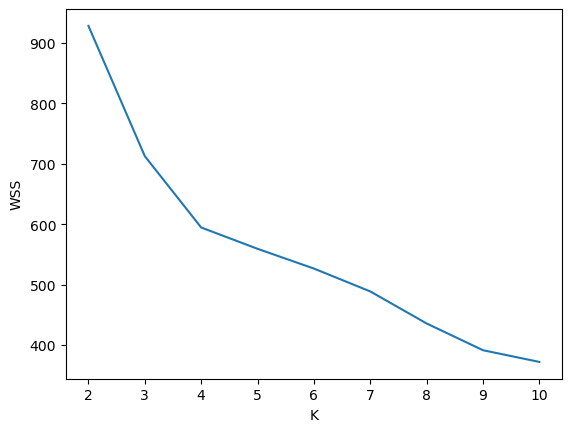

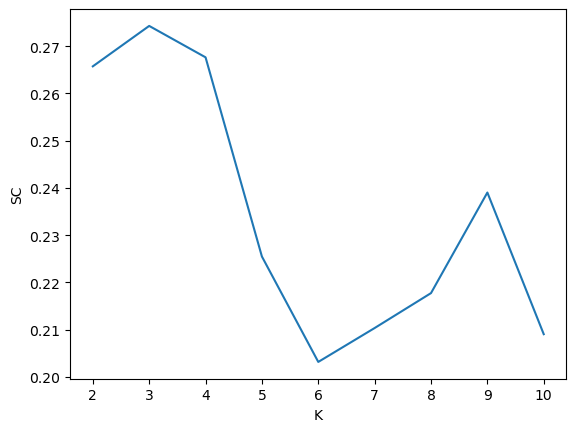

In [8]:
import matplotlib.pyplot as plt

plt.plot(valores_K, WSS)
plt.xlabel('K')
plt.ylabel('WSS')
plt.show()

plt.plot(valores_K, SC)
plt.xlabel('K')
plt.ylabel('SC')
plt.show()

Observando ambos gráficos, vemos que no es inmediato elegir el número ideal de clusters. La métrica de inercia sugiere K = 4, mientras que el SC proporciona valores similares para K = 3 y K = 4.

En este caso, vamos a basarnos en el "método del codo" (aunque ya hemos visto que no es el más robusto del mundo) y elegir K = 4 como nuestro número de clusters.

Tras ello, entrenamos el K-means definitivo.

In [ ]:
K = 4

kmeans = KMeans(n_clusters = K, random_state = 42)# Ajusta el modelo KMeans con K clusters
clusters = kmeans.fit_predict(X_norm)# Predice las etiquetas de cluster para los datos normalizados X_norm

# Creamos una columna con el índice del cluster
data_filtered['cluster'] = clusters# Añade la columna cluster al DataFrame data_filtered
data_filtered.head()# Muestra las primeras filas del DataFrame data_filtered

/var/folders/cv/rvsxw0dj5wn43y3zx05hkyzc0000gn/T/ipykernel_9062/640258416.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_filtered['cluster'] = clusters


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,score_anomaly,anomaly,cluster
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,0.077784,1,2
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,0.134844,1,1
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,0.102207,1,3
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200,0.118847,1,1
5,Argentina,14.5,18.9,8.10,16.0,18700,20.90,75.8,2.37,10300,0.082640,1,3


Vamos a extraer los países miembros de cada cluster, con el fin de comprobar e interpretar la agrupación realizada.

In [ ]:
for n in range(kmeans.n_clusters):# Iteramos por cada cluster
    print('Cluster %d' % n)
    print('-' * 10)
    
    df = data_filtered[data_filtered.cluster == n]# Filtramos los datos del cluster n
    
    print(df.country.tolist())
    print('')

Cluster 0
----------
['Australia', 'Austria', 'Bahamas', 'Bahrain', 'Belgium', 'Canada', 'Cyprus', 'Denmark', 'Finland', 'France', 'Germany', 'Greece', 'Iceland', 'Israel', 'Italy', 'Japan', 'Kuwait', 'Netherlands', 'New Zealand', 'Portugal', 'Slovenia', 'South Korea', 'Spain', 'Sweden', 'Switzerland', 'United Arab Emirates', 'United Kingdom']

Cluster 1
----------
['Albania', 'Antigua and Barbuda', 'Barbados', 'Belarus', 'Belize', 'Bhutan', 'Bosnia and Herzegovina', 'Botswana', 'Bulgaria', 'Cambodia', 'Cape Verde', 'Costa Rica', 'Croatia', 'Czech Republic', 'El Salvador', 'Estonia', 'Fiji', 'Georgia', 'Grenada', 'Guyana', 'Hungary', 'Jordan', 'Kyrgyz Republic', 'Latvia', 'Lebanon', 'Lithuania', 'Macedonia, FYR', 'Malaysia', 'Maldives', 'Mauritius', 'Micronesia, Fed. Sts.', 'Moldova', 'Montenegro', 'Morocco', 'Namibia', 'Panama', 'Paraguay', 'Poland', 'Romania', 'Samoa', 'Serbia', 'Slovak Republic', 'Solomon Islands', 'St. Vincent and the Grenadines', 'Suriname', 'Thailand', 'Tonga', '

Se observa que el cluster más numeroso es el 2. También resulta curioso que no haya homogeneidad en los continentes, sino que los clusters contienen países de todo el mundo.

Una de las interpretaciones que se puede hacer de este agrupamiento es que el cluster 0 contiene en general los países más desarrollados, los clusters 2 y 3 países en vías de desarrollo o de riqueza intermedia y el cluster 1 los países más pobres. Sin embargo, sería necesario mayor análisis y conocimiento experto para interpretar estos resultados.

In [ ]:
# Extraemos el vector de centroides

pd.DataFrame(sc.inverse_transform(kmeans.cluster_centers_), columns = list(df.columns)[1:-3])# Crea un DataFrame con los centroides desnormalizados
#inverse_transform: Deshace la normalización aplicada previamente
#cluster_centers_: Devuelve los centroides de los clusters encontrados por el modelo kmeans
#list(df.columns)[1:-3]: Crea una lista con los nombres de las columnas del DataFrame df, excluyendo la primera columna (country) y las últimas dos columnas (cluster y cualquier otra que no sea numérica).

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,5.066667,44.240741,9.137037,40.892593,39203.703704,2.284556,80.162963,1.779259,39192.592593
1,19.409615,47.888462,6.952885,59.334615,11825.000000,4.081231,72.357692,2.233654,6508.576923
2,89.054286,25.931714,6.213143,42.134286,2299.285714,8.615286,60.125714,5.103429,1021.514286
3,28.550000,30.760806,5.302778,28.671275,13366.666667,13.519167,72.313889,2.579722,6371.611111


## 4. Reducción de la dimensionalidad

En ocasiones manejar datasets con muchas variables puede ser complejo, tanto para su interpretabilidad como su modelización. Por ello, aplicar una análisis de componentes principales (PCA) es una buena idea para reducir su dimensión.

En este caso, vamos a reducir nuestro conjunto de datos de las 9 dimensiones originales a 2 dimensiones. Esto nos servirá también para poder visualizar los países.

Ajustamos el PCA utilizando el dataset original, con los 167 países. Previamente, normalizamos las variables de entrada.

In [ ]:
from sklearn.decomposition import PCA

# Normalización
sc = StandardScaler()
X = sc.fit_transform(data.drop('country', axis = 1))# Normaliza los datos sin la columna country
#fit : Calcula la media y desviación estándar de cada variable
#transform : Estandariza cada variable restando su media y dividiendo por su desviación estándar

# PCA 
pca = PCA(n_components = 2, random_state = 42)#pca con 2 componentes principales
X_new = pca.fit_transform(X)# Aplica PCA a los datos normalizados X

print(pca.explained_variance_ratio_)

[0.4595174  0.17181626]


In [ ]:
num_components = [2]

for comp in num_components:# Iteramos por el número de componentes
    pca = PCA(n_components = comp, random_state = 42)# Instancia PCA con comp componentes
    pca.fit(X)# Ajusta PCA a los datos normalizados X
    print(f"Número de componentes: {comp} | Varianza total explicada: {pca.explained_variance_ratio_.sum()}")

Número de componentes: 2 | Varianza total explicada: 0.631333654377141


Observamos que la primera componente preserva casi el 46% de la varianza, mientras que la segunda un 17% adicional. Es decir, la proyección en estas dos nuevas dimensiones conserva más del 60% de la varianza del dataset original.

In [21]:
print(X_new[:3,:])

data.head(3)

[[-2.91302459  0.09562058]
 [ 0.42991133 -0.58815567]
 [-0.28522508 -0.45517441]]


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460


In [ ]:
pca.components_.shape# Muestra la forma del array de componentes principales

(2, 9)

In [ ]:
pca.singular_values_# Muestra los valores singulares asociados a cada componente principal

array([26.28030915, 16.06984236])

## 5. Visualización final de los datos

Para concluir este cuaderno, vamos a combinar las 3 técnicas no supervisadas implementadas para visualizar los datos en 2D. Cada uno de los ejes se corresponderá con las componentes principales, y el color de cada país hará referencia a su cluster o si es una anomalía.

Para ello, vamos a combinar toda la información en un único dataframe.

In [ ]:
# Unir scores de anomalias y clusters
df_final = data_outliers.merge(
    data_filtered[['cluster']], left_index=True, right_index=True, how = 'left')
# Merge para unir data_outliers y data_filtered en base a los índices, data_filtered solo tiene filas sin outliers

# Añadir componentes principales
df_final[['pc1', 'pc2']] = X_new# Añade las columnas pc1 y pc2 con los componentes principales

# Crear columna category
df_final = df_final.fillna(-1)# Rellena los valores NaN con -1
df_final['category'] = df_final.cluster.apply(lambda x: "Cluster %d" % int(x) if x >= 0 else "Outlier")
# Crea la columna category basada en cluster
#df_final.cluster.apply(...) - Aplica una función a cada valor de la columna cluster
#lambda x: ... - Función anónima que recibe cada valor de cluster
#if x >= 0 - Evalúa si el valor es 0 o mayor (país con cluster asignado)
#Si es verdadero: devuelve "Cluster %d" % int(x) → ejemplo: "Cluster 0", "Cluster 1", etc.
#Si es falso (x < 0): devuelve "Outlier"

df_final[['country', 'score_anomaly', 'category', 'pc1', 'pc2']].sample(10)# Muestra 10 registros al azar con las columnas especificadas

,country,score_anomaly,category,pc1,pc2
139,Spain,0.091838,Cluster 0,2.019197,-1.784382
148,Thailand,0.098337,Cluster 1,0.926093,0.828231
20,Bosnia and Herzegovina,0.107721,Cluster 1,0.995867,-0.971888
3,Angola,-0.005250,Outlier,-2.932423,1.695555
118,Paraguay,0.135747,Cluster 1,0.117846,0.361031
156,Ukraine,0.101668,Cluster 1,0.302300,-0.097571
105,Morocco,0.119185,Cluster 1,-0.232870,-0.281028
53,Finland,0.089325,Cluster 0,2.458960,-1.076143
29,Canada,0.069902,Cluster 0,2.543631,-1.727095
61,Grenada,0.123463,Cluster 1,0.145505,-0.431336


Finalmente, creamos un gráfico interactivo con esta información.

**Nota**: para ejecutar la siguiente celda, es necesario instalar previamente el paquete `mpld3`. Se puede hacer con el comando `pip install mpld3`.

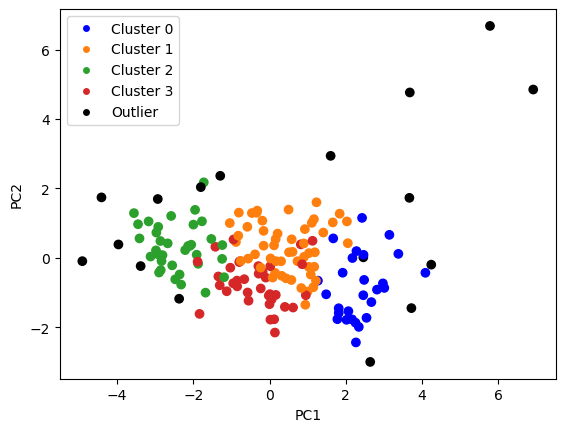

In [ ]:
import mpld3
from matplotlib.lines import Line2D

fig, ax = plt.subplots()

colors = {
    'Cluster 0': '#0000FF', 'Cluster 1': '#ff7f0e', 
    'Cluster 2': '#2ca02c', 'Cluster 3': '#d62728',
    'Outlier':'#000000'
}

scatter = ax.scatter(df_final.pc1, df_final.pc2, c = df_final['category'].map(colors).tolist())# Crea un scatter plot de pc1 vs pc2, coloreado por categoría

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')

handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=v, label=k, markersize=6) for k, v in colors.items()]
# Crea leyendas personalizadas para cada categoría
ax.legend(handles = handles, loc = 'best')

labels = df_final.country.tolist()# Obtiene la lista de países para los tooltips
tooltip = mpld3.plugins.PointLabelTooltip(scatter, labels=labels)# Crea un tooltip con los nombres de los países
mpld3.plugins.connect(fig, tooltip)# Conecta el tooltip al scatter plot

mpld3.enable_notebook()# Habilita la visualización interactiva en el notebook

## 6. Conclusiones

En este cuaderno hemos implementado diferentes métodos de aprendizaje no supervisado utilizando scikit-learn. Con el algoritmo Isolation Forest hemos identificado registros outliers, con el K-means hemos creado agrupaciones en los datos y con PCA hemos conseguido representar el dataset en 2D.

Los problemas de aprendizaje no supervisado con menos habituales que los supervisados. Sin embargo, es importante tenerlos presentes ya que permiten extraer patrones relevantes de los conjuntos de datos y entender mejor la información, algo fundamental cuando queremos resolver un problema con Machine Learning.

## Ejercicios propuestos

- Utilice el algoritmo no supervisado DBSCAN para detectar outliers y generar clusters simultáneamente. Compare su rendimiento con los modelos Isolation Forest y K-Means. ¿Se obtienen los mismos clusters y los mismos outliers?
- Calcule la varianza total explicada utilizando PCA para diferentes valores del número de componentes, y represente gráficamente los resultados.